# VDUI Unit 4 - PPT 7 Activity

**Student Name:** A Sheiman Joshi  
**SRN:** PES2UG24CS003  
**Section:** Section A  
**Subject:** Visual Design and User Interface (UE24CS342AA9)  
**Unit:** Unit 4 - AI-Assisted and Advanced Visualization  


# Demo: Bias, Model Drift and Responsible AI Visualization

**Unit 4 · AI-Assisted and Advanced Visualization · Lecture 7**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

This notebook walks through every topic of the lecture with **one synthetic dataset** (applications scored by an AI **resume-screening model**, with the true interview outcome known) plus small synthetic series for drift, Simpson's paradox, multiple comparisons and explainability. It needs no internet and **no API key**.

> The groups are called **Group A** and **Group B** on purpose: the methods are the same whatever the attribute (region, language, age band, gender…). All data are synthetic; no real people or companies are described.

| Section | Lecture topic |
|---|---|
| 1–2 | Bias in AI-driven insights: data, model, visualization and interpretation bias |
| 3 | Selection and sampling bias; visual checks |
| 4–6 | Fairness visualization; subgroup comparisons and Simpson's paradox; group thresholds and error-rate gaps |
| 7–12 | Model drift: data vs concept drift, PSI and KS, performance degradation, delayed labels, monitoring dashboards, annotating drift events |
| 13–14 | AI-generated insight errors; misuse of automated insights (multiple comparisons) |
| 15–17 | Automation bias; explainability limitations; uncertainty and ambiguity |
| 18–19 | Human oversight; nested-model validation; responsible practice; model cards |
| 20–21 | Visualization bias (ugly, bad, wrong); interpretation bias; clutter, attention and storytelling |
| 22 | Numericals 1–5 |

In [1]:
import itertools, textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE, LIGHT = "#bdbdbd", "#d95f02", "#4c78a8", "#e6e6e6"
GCOL = {"A": BLUE, "B": ACCENT}

## 1 · Bias in AI-driven insights

**Bias** here means a *systematic, repeatable distortion* that favours some outcomes or groups, or misleads the person reading the result. It can enter at every stage: collection, labels, training and thresholds, drawing, and reading (Suresh & Guttag 2021). Wilke (Ch. 1): a visualization must first **accurately convey the data**; it must not mislead or distort. Visualization can **expose** bias (compare groups) and can **create** it (hide groups in an aggregate).

| Kind | Where it arises | Example | How visualization helps or hurts |
|---|---|---|---|
| Data bias | collection, labels, representation | a group barely present in training data; cost used as a proxy for need (Obermeyer et al. 2019) | compare sample with population; show counts per group |
| Model bias | objective, features, thresholds | higher error rate for one group at a single threshold | per-group metrics; threshold sweeps |
| Visualization bias | encoding and aggregation choices | a pooled trend hiding subgroups; selective ranges | show subgroups and denominators |
| Interpretation bias | the viewer | confirmation bias; over-trust in highlighted AI output | show alternatives, uncertainty, limits |

## 2 · The synthetic dataset: an AI resume screener

6,000 applications. **Group B** makes up 40% of applicants but only **12% of the historical training data**. The true outcome `qualified` comes from a later structured interview. The model was trained on **past hiring decisions** (a proxy label that carried an old preference for "Tier-1" colleges, which Group B attended less often).

In [2]:
rng = np.random.default_rng(7)
N = 6000
group = np.where(rng.random(N) < 0.40, "B", "A")
tier1 = rng.random(N) < np.where(group == "A", 0.55, 0.15)
skill = rng.normal(0, 1, N)
exp_y = rng.gamma(2.5, 1.6, N).round(1)
qual_logit = -0.3 + 1.6 * skill + 0.25 * (exp_y - 4) + 0.15 * tier1
qualified = (rng.random(N) < 1 / (1 + np.exp(-qual_logit))).astype(int)
apps = pd.DataFrame({"app_id": [f"R{10000 + i}" for i in range(N)], "group": group, "tier1_college": tier1.astype(int),
                     "skill_test": skill.round(2), "experience_yrs": exp_y, "qualified": qualified})

# the historical label: past hiring decisions, which over-rewarded Tier-1 colleges
past_hire = (rng.random(N) < 1 / (1 + np.exp(-(qual_logit + 2.4 * tier1 - 1.0)))).astype(int)
train_idx = np.r_[rng.choice(np.where(group == "A")[0], 1760, replace=False), rng.choice(np.where(group == "B")[0], 240, replace=False)]
feats = ["skill_test", "experience_yrs", "tier1_college"]
model = LogisticRegression().fit(apps.loc[train_idx, feats], past_hire[train_idx])
apps["score"] = model.predict_proba(apps[feats])[:, 1].round(3)
THR = 0.5
apps["shortlisted"] = (apps.score >= THR).astype(int)
ev = apps.drop(index=train_idx).reset_index(drop=True)                  # evaluate on applicants the model did not see
print(f"evaluation applicants: {len(ev)} | Group B share: population {np.mean(group == 'B'):.0%}, training {np.mean(group[train_idx] == 'B'):.0%}")
print("model coefficients:", dict(zip(feats, model.coef_[0].round(2))))
ev.head()

evaluation applicants: 4000 | Group B share: population 41%, training 12%
model coefficients: {'skill_test': np.float64(1.51), 'experience_yrs': np.float64(0.24), 'tier1_college': np.float64(2.4)}


,app_id,group,tier1_college,skill_test,experience_yrs,qualified,score,shortlisted
0,R10000,A,1,0.60,8.2,1,0.951,1
1,R10003,B,0,-0.40,1.6,0,0.074,0
2,R10004,B,0,0.47,7.9,1,0.575,1
3,R10008,A,0,-0.13,4.1,0,0.179,0
4,R10011,B,0,-0.79,1.5,0,0.041,0


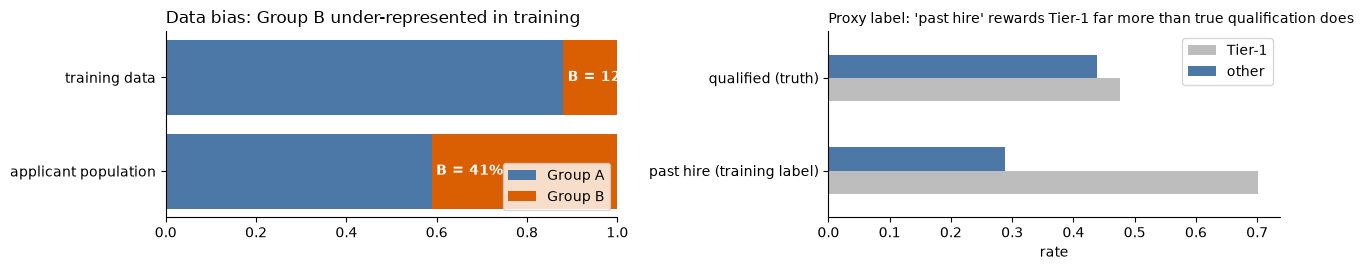

In [3]:
comp = pd.DataFrame({"applicant population": pd.Series(group).value_counts(normalize=True), "training data": pd.Series(group[train_idx]).value_counts(normalize=True)}).T
fig, ax = plt.subplots(1, 2, figsize=(13, 2.8))
left = np.zeros(2)
for g_ in ["A", "B"]:
    ax[0].barh(comp.index, comp[g_], left=left, color=GCOL[g_], label=f"Group {g_}"); left += comp[g_].values
for i, (_, r) in enumerate(comp.iterrows()): ax[0].text(r.A + .01, i, f"B = {r.B:.0%}", va="center", color="w", fontweight="bold")
ax[0].legend(loc="lower right"); ax[0].set_xlim(0, 1); ax[0].set_title("Data bias: Group B under-represented in training", loc="left")
lab = pd.DataFrame({"past hire (training label)": [past_hire[tier1].mean(), past_hire[~tier1].mean()], "qualified (truth)": [qualified[tier1].mean(), qualified[~tier1].mean()]}, index=["Tier-1", "other"])
lab.T.plot.barh(ax=ax[1], color=[GREY, BLUE]); ax[1].set_xlabel("rate"); ax[1].set_title("Proxy label: 'past hire' rewards Tier-1 far more than true qualification does", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 3 · Selection and sampling bias

If cases enter the data **because of their outcome**, the observed relationship is distorted. Classic example: the company only knows the job performance of people it **hired**, so a model of "skill → performance" learnt from hires sees a restricted range, and **the slope and correlation shrink**.

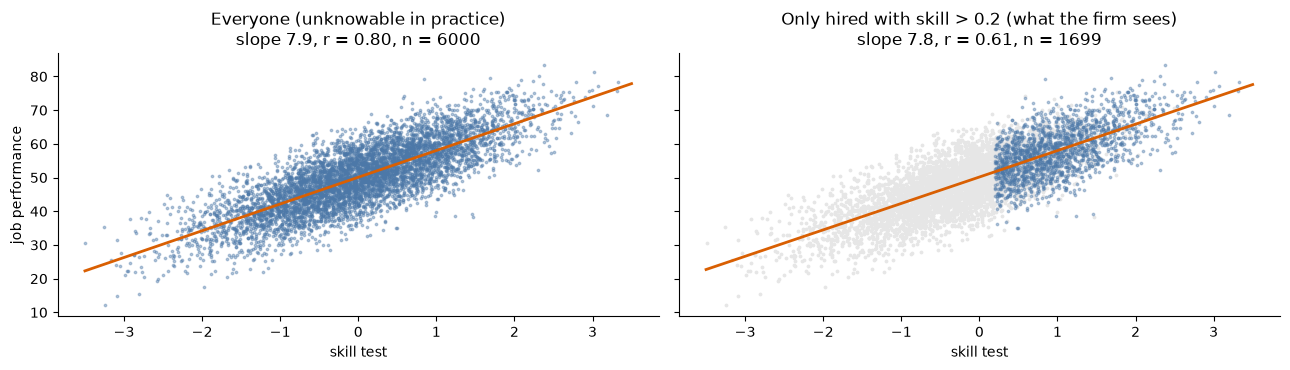

In [4]:
perf = 50 + 8 * skill + rng.normal(0, 6, N)
seen = past_hire == 1
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
for a_, m_, title in [(ax[0], np.ones(N, bool), "Everyone (unknowable in practice)"), (ax[1], seen & (skill > 0.2), "Only hired with skill > 0.2 (what the firm sees)")]:
    a_.scatter(skill[~m_], perf[~m_], s=3, color=LIGHT); a_.scatter(skill[m_], perf[m_], s=3, color=BLUE, alpha=.4)
    lr = stats.linregress(skill[m_], perf[m_]); gx = np.linspace(-3.5, 3.5, 10)
    a_.plot(gx, lr.intercept + lr.slope * gx, color=ACCENT, lw=2); a_.set_title(f"{title}\nslope {lr.slope:.1f}, r = {lr.rvalue:.2f}, n = {m_.sum()}")
    a_.set_xlabel("skill test")
ax[0].set_ylabel("job performance"); plt.tight_layout(); plt.show()

### Visual checks for sampling bias (Wilke Ch. 7–8, 22)
Compare the sample's distributions with a known population using **ECDFs**; plot **missingness by group**; **show n behind every bar**; ask what is *not* in the data; state the sampling frame on the figure.

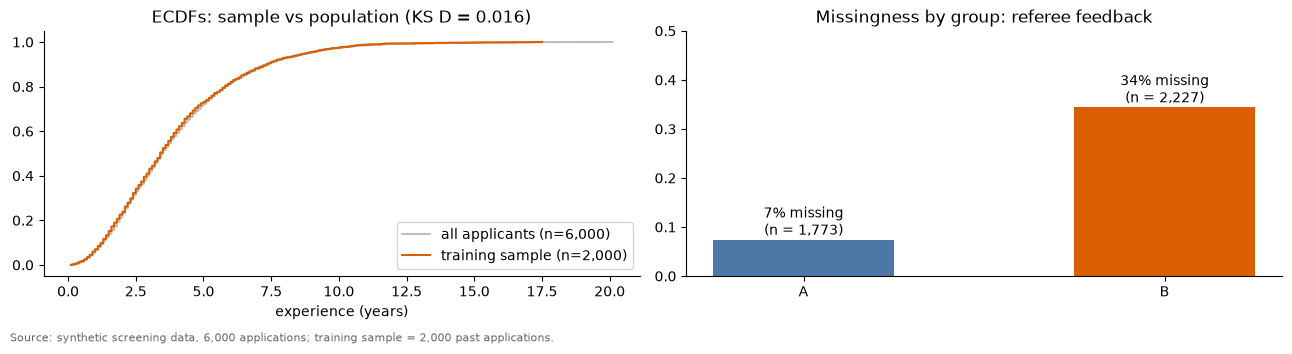

In [5]:
ev["referee_feedback"] = np.where(rng.random(len(ev)) < np.where(ev.group == "A", .08, .35), np.nan, rng.normal(3.5, .6, len(ev)).round(1))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
for lab_, v, col in [("all applicants", apps.experience_yrs, GREY), ("training sample", apps.experience_yrs.iloc[train_idx], ACCENT)]:
    x_ = np.sort(v); ax[0].step(x_, np.arange(1, len(x_) + 1) / len(x_), color=col, label=f"{lab_} (n={len(v):,})")
ks = stats.ks_2samp(apps.experience_yrs, apps.experience_yrs.iloc[train_idx])
ax[0].legend(); ax[0].set_xlabel("experience (years)"); ax[0].set_title(f"ECDFs: sample vs population (KS D = {ks.statistic:.3f})")
miss = ev.groupby("group").referee_feedback.apply(lambda s: s.isna().mean()); n_g = ev.group.value_counts()
ax[1].bar(miss.index, miss.values, color=[GCOL[g_] for g_ in miss.index], width=.5)
for g_, v in miss.items(): ax[1].text(g_, v + .01, f"{v:.0%} missing\n(n = {n_g[g_]:,})", ha="center")
ax[1].set_ylim(0, .5); ax[1].set_title("Missingness by group: referee feedback")
fig.text(.01, -.02, "Source: synthetic screening data, 6,000 applications; training sample = 2,000 past applications.", fontsize=8, color="#666")
plt.tight_layout(); plt.show()

## 4 · Fairness visualization

Fairness views compare how a model treats groups. Different definitions encode different values (Hardt et al. 2016):

| Measure | Question it asks | Equal across groups |
|---|---|---|
| Demographic parity | selected at the same rate? | selection rate |
| Equal opportunity | qualified people found equally often? | true-positive rate |
| Equalized odds | both error types equal? | TPR and FPR |
| Predictive parity | is a positive prediction equally trustworthy? | precision |
| Group calibration | does a score mean the same thing? | calibration curve |

When base rates differ, these criteria **generally cannot all hold at once** (Chouldechova 2017; Kleinberg et al. 2017), so the display should make the trade-off visible. Tools: What-If Tool (Wexler et al. 2020), FairVis (Cabrera et al. 2019).

,n,base rate,selection rate,TPR,FPR,precision
A,1773.0,0.470,0.507,0.700,0.336,0.648
B,2227.0,0.446,0.286,0.482,0.127,0.753


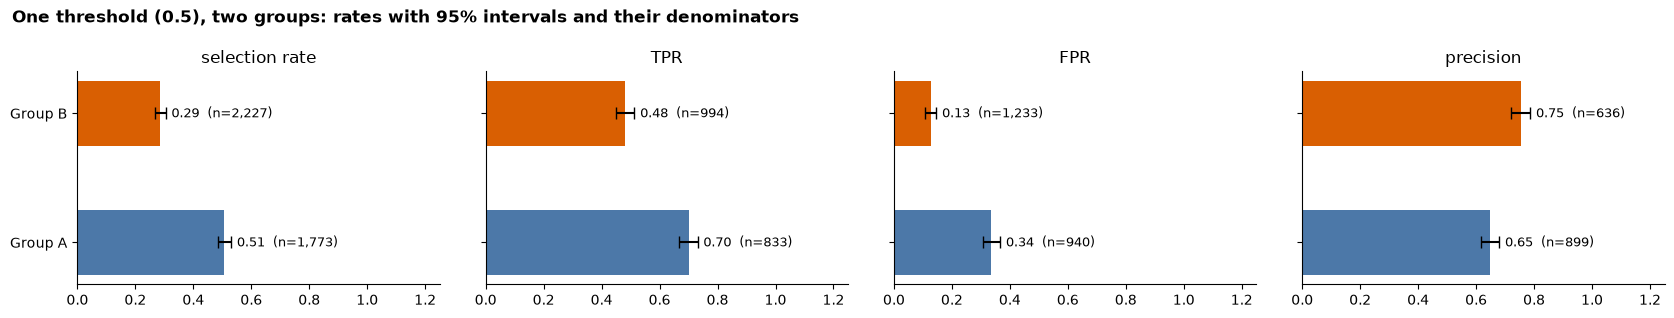

Equal-opportunity gap (TPR A − B) = 0.22 | selection-rate ratio B/A = 0.56 (four-fifths rule of thumb: 0.8)


In [6]:
def group_metrics(d, pred_col="shortlisted"):
    rows = {}
    for g_, t in d.groupby("group"):
        y, p = t.qualified.values, t[pred_col].values
        tp, fp, fn, tn = ((p == 1) & (y == 1)).sum(), ((p == 1) & (y == 0)).sum(), ((p == 0) & (y == 1)).sum(), ((p == 0) & (y == 0)).sum()
        rows[g_] = {"n": len(t), "base rate": y.mean(), "selection rate": p.mean(), "TPR": tp / (tp + fn), "FPR": fp / (fp + tn), "precision": tp / max(tp + fp, 1),
                    "n_pos": tp + fn, "n_neg": fp + tn, "n_sel": tp + fp}
    return pd.DataFrame(rows).T

gm = group_metrics(ev)
display(gm[["n", "base rate", "selection rate", "TPR", "FPR", "precision"]].astype(float).round(3))

fig, ax = plt.subplots(1, 4, figsize=(17, 3.2), sharey=True)
for a_, (m_, den) in zip(ax, [("selection rate", "n"), ("TPR", "n_pos"), ("FPR", "n_neg"), ("precision", "n_sel")]):
    for i, g_ in enumerate(["A", "B"]):
        v, n_ = gm.loc[g_, m_], gm.loc[g_, den]; se = np.sqrt(v * (1 - v) / n_)
        a_.barh(i, v, color=GCOL[g_], height=.5, xerr=1.96 * se, capsize=4); a_.text(v + 1.96 * se + .02, i, f"{v:.2f}  (n={int(n_):,})", va="center", fontsize=9)
    a_.set_xlim(0, 1.25); a_.set_title(m_); a_.set_yticks([0, 1]); a_.set_yticklabels(["Group A", "Group B"])
fig.suptitle(f"One threshold ({THR}), two groups: rates with 95% intervals and their denominators", x=.01, ha="left", fontweight="bold")
plt.tight_layout(); plt.show()
print(f"Equal-opportunity gap (TPR A − B) = {gm.loc['A', 'TPR'] - gm.loc['B', 'TPR']:.2f} | selection-rate ratio B/A = {gm.loc['B', 'selection rate'] / gm.loc['A', 'selection rate']:.2f} (four-fifths rule of thumb: 0.8)")

### Group calibration: does a score mean the same thing for both groups?

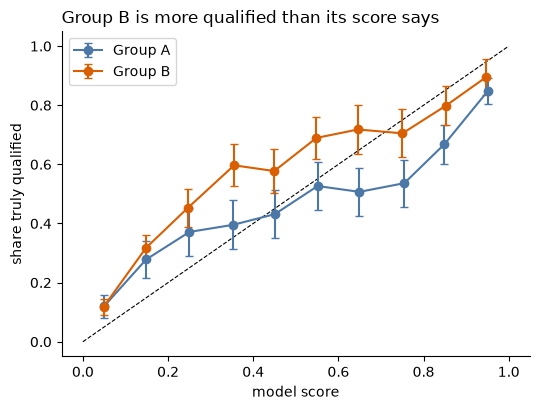

In [7]:
fig, ax = plt.subplots(figsize=(5.5, 4.2))
ax.plot([0, 1], [0, 1], "k--", lw=.8)
for g_, t in ev.groupby("group"):
    b_ = t.groupby(pd.cut(t.score, np.linspace(0, 1, 11)), observed=True).agg(s=("score", "mean"), q=("qualified", "mean"), n=("qualified", "size"))
    b_ = b_[b_.n >= 20]
    ax.errorbar(b_.s, b_.q, yerr=1.96 * np.sqrt(b_.q * (1 - b_.q) / b_.n), fmt="o-", color=GCOL[g_], capsize=3, label=f"Group {g_}")
ax.set_xlabel("model score"); ax.set_ylabel("share truly qualified"); ax.legend(); ax.set_title("Group B is more qualified than its score says", loc="left")
plt.tight_layout(); plt.show()

## 5 · Subgroup comparisons and Simpson's paradox

A **pooled trend can point one way while every subgroup points the other**: aggregation hid a grouping variable. Synthetic example: across five offices, offices that send more applicants to the AI screener *seem* to hire better people… until we split by job family.

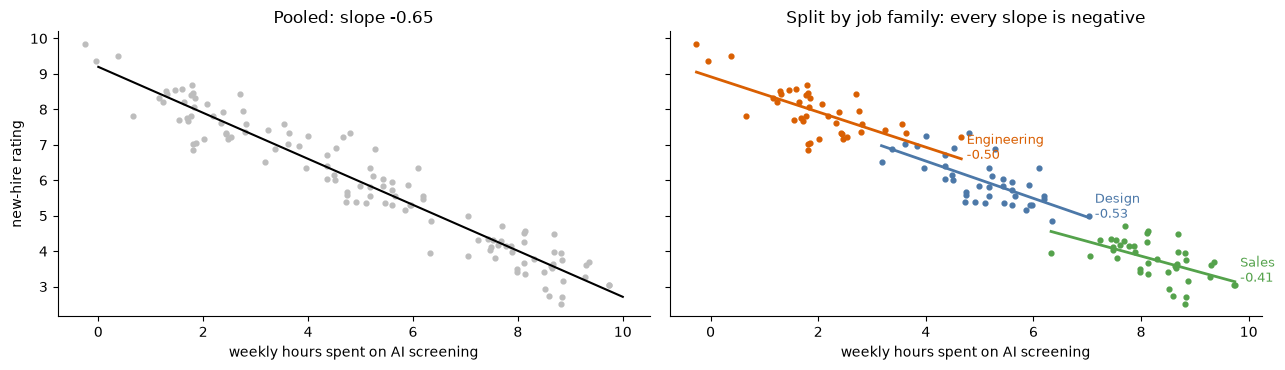

In [8]:
rs = np.random.default_rng(3)
rows = []
for fam, (x0, y0) in {"Engineering": (2, 8), "Design": (5, 6), "Sales": (8, 4)}.items():
    x_ = x0 + rs.normal(0, .8, 40); y_ = y0 + 0.5 * (x_ - x0) * -1 + rs.normal(0, .5, 40)
    rows.append(pd.DataFrame({"family": fam, "x": x_, "y": y_}))
sp = pd.concat(rows)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
lr_all = stats.linregress(sp.x, sp.y)
ax[0].scatter(sp.x, sp.y, s=12, color=GREY); gx = np.linspace(0, 10, 10); ax[0].plot(gx, lr_all.intercept + lr_all.slope * gx, color="k")
ax[0].set_title(f"Pooled: slope {lr_all.slope:+.2f}"); ax[0].set_xlabel("weekly hours spent on AI screening"); ax[0].set_ylabel("new-hire rating")
for (fam, t), col in zip(sp.groupby("family"), [BLUE, ACCENT, "#54a24b"]):
    l_ = stats.linregress(t.x, t.y); ax[1].scatter(t.x, t.y, s=12, color=col); xx_ = np.linspace(t.x.min(), t.x.max(), 5)
    ax[1].plot(xx_, l_.intercept + l_.slope * xx_, color=col, lw=2); ax[1].text(t.x.max() + .1, l_.intercept + l_.slope * t.x.max(), f"{fam}\n{l_.slope:+.2f}", color=col, fontsize=9)
ax[1].set_title("Split by job family: every slope is negative"); ax[1].set_xlabel("weekly hours spent on AI screening")
plt.tight_layout(); plt.show()

### Designing subgroup comparisons
* **Small multiples or grouped bars with the same axes** (Knaflic Ch. 3: alignment and consistency reduce effort).
* **Show n per group**: small groups carry wide uncertainty; SE shrinks only as n grows (Wilke Ch. 16).
* Intersectional cells can be tiny: **add intervals or suppress cells that are too thin**.
* Treat gaps as findings; do not bury them in an average.

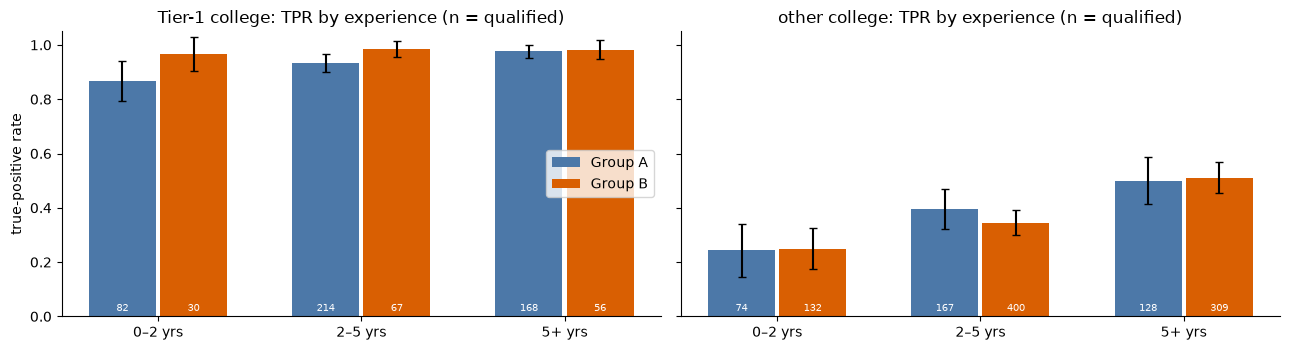

In [9]:
ev["exp_band"] = pd.cut(ev.experience_yrs, [0, 2, 5, 30], labels=["0–2 yrs", "2–5 yrs", "5+ yrs"])
ev["college"] = np.where(ev.tier1_college == 1, "Tier-1", "other")
cells = ev.groupby(["college", "exp_band", "group"], observed=True).apply(
    lambda t: pd.Series({"n": len(t), "TPR": ((t.shortlisted == 1) & (t.qualified == 1)).sum() / max((t.qualified == 1).sum(), 1), "pos": (t.qualified == 1).sum()}), include_groups=False).reset_index()
MIN_POS = 30
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6), sharey=True)
for a_, col_ in zip(ax, ["Tier-1", "other"]):
    sub = cells[cells.college == col_]
    for k_, g_ in enumerate(["A", "B"]):
        s_ = sub[sub.group == g_]
        for _, r in s_.iterrows():
            i = ["0–2 yrs", "2–5 yrs", "5+ yrs"].index(r.exp_band); x_ = i + (k_ - .5) * .35
            if r.pos < MIN_POS:
                a_.text(x_, .05, f"n={int(r.pos)}\nsuppressed", ha="center", fontsize=7, color="#888"); continue
            se = np.sqrt(r.TPR * (1 - r.TPR) / r.pos)
            a_.bar(x_, r.TPR, width=.33, color=GCOL[g_], yerr=1.96 * se, capsize=3, label=f"Group {g_}" if i == 0 else None)
            a_.text(x_, .02, f"{int(r.pos)}", ha="center", color="w", fontsize=7)
    a_.set_xticks(range(3)); a_.set_xticklabels(["0–2 yrs", "2–5 yrs", "5+ yrs"]); a_.set_title(f"{col_} college: TPR by experience (n = qualified)"); a_.set_ylim(0, 1.05)
ax[0].legend(); ax[0].set_ylabel("true-positive rate"); plt.tight_layout(); plt.show()

## 6 · Group thresholds and error-rate gaps

One threshold, different groups: **error rates differ when score distributions differ**. Group-specific thresholds can equalise one rate, but they **move the others**. Show all the rates side by side.

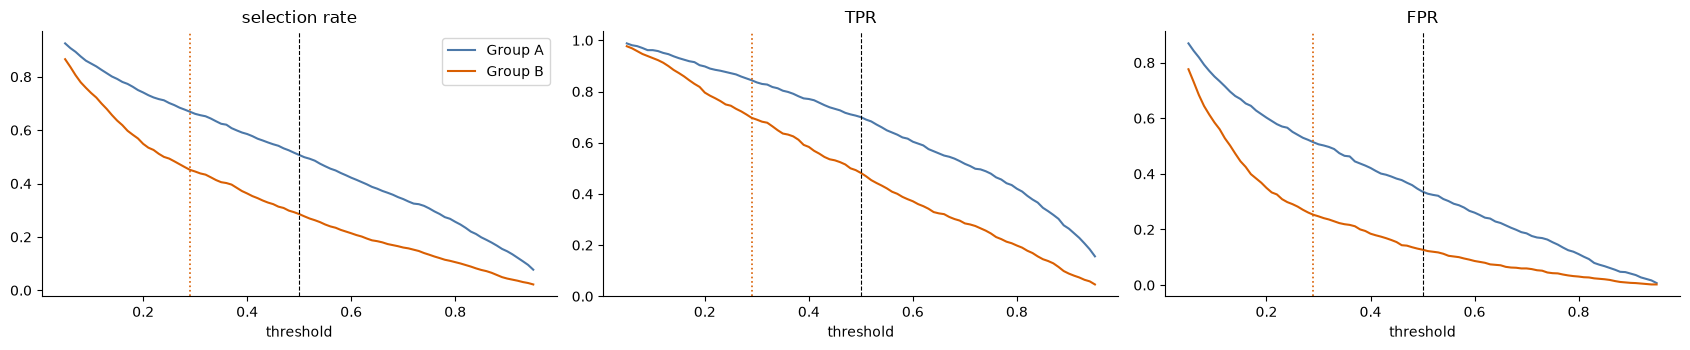

A                     B              
                                selection  TPR    FPR selection    TPR    FPR
single threshold 0.50               0.507  0.7  0.336     0.286  0.482  0.127
B uses 0.29 (equal opportunity)     0.507  0.7  0.336     0.451  0.697  0.253

Equalising TPR closes the opportunity gap but raises Group B's FPR and selection rate: the trade-off must be visible to decision makers.


In [10]:
grid = np.linspace(.05, .95, 91)
def rates(t, thr):
    p = t.score >= thr; y = t.qualified == 1
    return p.mean(), (p & y).sum() / y.sum(), (p & ~y).sum() / (~y).sum()
sweep = {g_: np.array([rates(t, th) for th in grid]) for g_, t in ev.groupby("group")}
target_tpr = rates(ev[ev.group == "A"], THR)[1]
thr_B = grid[np.argmin(np.abs(sweep["B"][:, 1] - target_tpr))]
fig, ax = plt.subplots(1, 3, figsize=(17, 3.6))
for k_, lab_ in enumerate(["selection rate", "TPR", "FPR"]):
    for g_ in "AB": ax[k_].plot(grid, sweep[g_][:, k_], color=GCOL[g_], label=f"Group {g_}")
    ax[k_].axvline(THR, color="k", ls="--", lw=.8); ax[k_].axvline(thr_B, color=ACCENT, ls=":", lw=1.2); ax[k_].set_title(lab_); ax[k_].set_xlabel("threshold")
ax[0].legend(); plt.tight_layout(); plt.show()
cmp_ = pd.DataFrame({"single threshold 0.50": [*rates(ev[ev.group == "A"], THR), *rates(ev[ev.group == "B"], THR)],
                     f"B uses {thr_B:.2f} (equal opportunity)": [*rates(ev[ev.group == "A"], THR), *rates(ev[ev.group == "B"], thr_B)]},
                    index=pd.MultiIndex.from_product([["A", "B"], ["selection", "TPR", "FPR"]])).round(3)
display(cmp_.T)
print("Equalising TPR closes the opportunity gap but raises Group B's FPR and selection rate: the trade-off must be visible to decision makers.")

## 7 · Model drift: data drift vs concept drift

After deployment the world changes. A drift view should answer: **has something changed, which feature or segment, when, and by how much?** and support the next decision (investigate, retrain, restrict use). Long-term monitoring of automatic systems is one of Munzner's reasons for a human in the loop (§1.2).

| | Data (covariate) drift | Concept drift | Label (prior) drift |
|---|---|---|---|
| What changes | distribution of inputs | relationship inputs → label | frequency of each label |
| Example | applicants get more experienced | same CV now means something different | qualified share falls |
| Detectable from inputs alone? | yes | not without labels or proxies | partly, from predictions |
| Typical view | reference vs current histograms | accuracy over time; error cases | class share over time |

### Data drift: overlay this week on the reference, and track a drift statistic

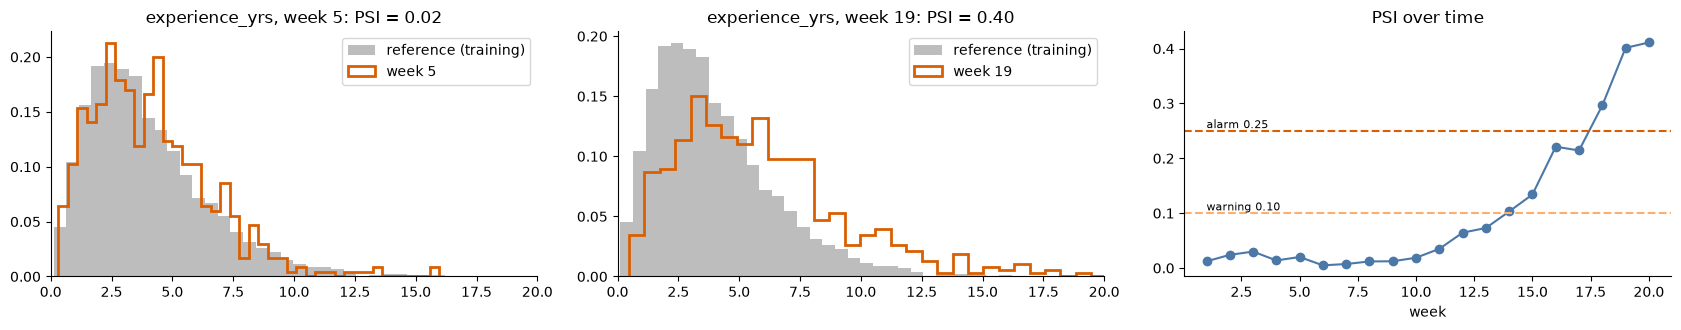

In [11]:
def psi(ref, cur, bins=10):
    edges = np.quantile(ref, np.linspace(0, 1, bins + 1)); edges[0], edges[-1] = -np.inf, np.inf
    e = np.histogram(ref, edges)[0] / len(ref); a = np.histogram(cur, edges)[0] / len(cur)
    e, a = np.clip(e, 1e-4, None), np.clip(a, 1e-4, None)
    return float(((a - e) * np.log(a / e)).sum())

rs = np.random.default_rng(10)
ref = rs.gamma(2.5, 1.6, 5000)
weeks = [rs.gamma(2.5, 1.6 * (1 + max(0, w - 8) * 0.045), 600) for w in range(20)]       # drift starts in week 9
psis = [psi(ref, w_) for w_ in weeks]
fig, ax = plt.subplots(1, 3, figsize=(17, 3.4))
for a_, w in zip(ax[:2], [4, 18]):
    a_.hist(ref, bins=40, density=True, color=GREY, label="reference (training)"); a_.hist(weeks[w], bins=40, density=True, histtype="step", lw=2, color=ACCENT, label=f"week {w + 1}")
    a_.set_title(f"experience_yrs, week {w + 1}: PSI = {psis[w]:.2f}"); a_.legend(); a_.set_xlim(0, 20)
ax[2].plot(range(1, 21), psis, marker="o", color=BLUE); ax[2].axhline(.1, color="#fdae6b", ls="--"); ax[2].axhline(.25, color=ACCENT, ls="--")
ax[2].text(1, .105, "warning 0.10", fontsize=8); ax[2].text(1, .255, "alarm 0.25", fontsize=8); ax[2].set_xlabel("week"); ax[2].set_title("PSI over time")
plt.tight_layout(); plt.show()

### Measuring drift: PSI, KS and friends
* **PSI** = Σ (aᵢ − eᵢ) ln(aᵢ/eᵢ) over reference bins. Rule of thumb (credit-risk practice): < 0.10 stable, 0.10–0.25 moderate, > 0.25 significant.
* **Kolmogorov–Smirnov D**: the largest vertical gap between two ECDFs (Wilke Ch. 8).
* Others: Jensen–Shannon divergence; per-feature drift heatmaps.
* **With very large samples, tiny shifts become statistically significant: judge the practical size too.**

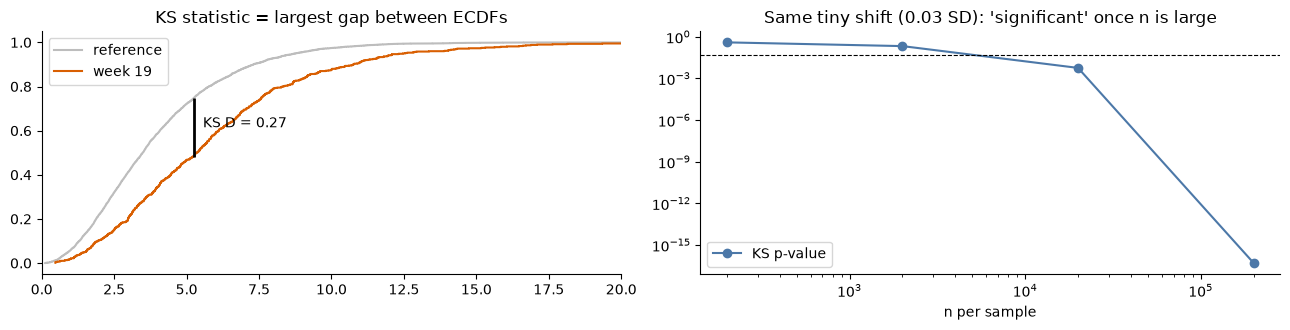

,n per sample,KS p-value (median of 15),PSI (median of 15)
0,200,0.3935,0.0889
1,2000,0.2117,0.0096
2,20000,0.0057,0.0017
3,200000,0.0000,0.0011


In [12]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
cur = weeks[18]
for v, col, lab_ in [(ref, GREY, "reference"), (cur, ACCENT, "week 19")]:
    x_ = np.sort(v); ax[0].step(x_, np.arange(1, len(x_) + 1) / len(x_), color=col, label=lab_)
grid_x = np.linspace(0, 20, 2000)
F1 = np.searchsorted(np.sort(ref), grid_x, side="right") / len(ref); F2 = np.searchsorted(np.sort(cur), grid_x, side="right") / len(cur)
k_ = np.argmax(np.abs(F1 - F2)); ax[0].vlines(grid_x[k_], F2[k_], F1[k_], color="k", lw=2); ax[0].text(grid_x[k_] + .3, (F1[k_] + F2[k_]) / 2, f"KS D = {abs(F1[k_] - F2[k_]):.2f}")
ax[0].legend(); ax[0].set_xlim(0, 20); ax[0].set_title("KS statistic = largest gap between ECDFs")
rows = []
for n_ in [200, 2000, 20000, 200000]:
    reps = [(stats.ks_2samp(a1, a2).pvalue, psi(a1, a2)) for a1, a2 in ((rs.normal(0, 1, n_), rs.normal(0.03, 1, n_)) for _ in range(15))]
    rows.append((n_, *np.median(reps, axis=0)))
tiny = pd.DataFrame(rows, columns=["n per sample", "KS p-value (median of 15)", "PSI (median of 15)"])
ax[1].plot(tiny["n per sample"], tiny["KS p-value (median of 15)"], marker="o", color=BLUE, label="KS p-value"); ax[1].axhline(.05, color="k", ls="--", lw=.8)
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("n per sample"); ax[1].legend(); ax[1].set_title("Same tiny shift (0.03 SD): 'significant' once n is large")
plt.tight_layout(); plt.show()
display(tiny.round(4))

## 8 · Concept drift

The inputs look the same, but **the rule linking them to the label moves**. A fixed model's accuracy falls as the true boundary rotates away. Plot **errors on the data** and **accuracy over time** together.

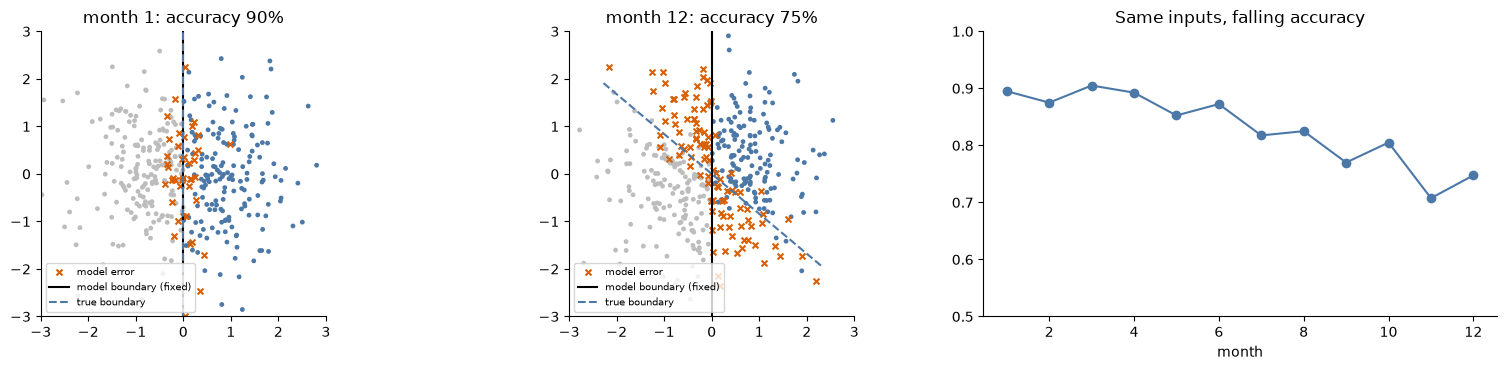

In [13]:
rs = np.random.default_rng(4)
angles = np.radians(np.linspace(0, 50, 12))
acc_t, snaps = [], {}
w_model = np.array([1.0, 0.0])
for m_, ang in enumerate(angles):
    Xm = rs.normal(0, 1, (400, 2)); w_true = np.array([np.cos(ang), np.sin(ang)])
    ym = (Xm @ w_true + rs.normal(0, .3, 400) > 0).astype(int); pm = (Xm @ w_model > 0).astype(int)
    acc_t.append((pm == ym).mean())
    if m_ in (0, 11): snaps[m_] = (Xm, ym, pm, w_true)
fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
for a_, m_ in zip(ax[:2], (0, 11)):
    Xm, ym, pm, w_true = snaps[m_]
    a_.scatter(Xm[pm == ym, 0], Xm[pm == ym, 1], s=6, c=np.where(ym[pm == ym] == 1, BLUE, GREY))
    a_.scatter(Xm[pm != ym, 0], Xm[pm != ym, 1], s=18, color=ACCENT, marker="x", label="model error")
    gl = np.linspace(-3, 3, 10)
    a_.plot(gl * 0, gl, color="k", lw=1.5, label="model boundary (fixed)"); a_.plot(-w_true[1] * gl, w_true[0] * gl, color=BLUE, ls="--", label="true boundary")
    a_.set_xlim(-3, 3); a_.set_ylim(-3, 3); a_.set_aspect("equal"); a_.set_title(f"month {m_ + 1}: accuracy {acc_t[m_]:.0%}"); a_.legend(fontsize=7, loc="lower left")
ax[2].plot(range(1, 13), acc_t, marker="o", color=BLUE); ax[2].set_ylim(.5, 1); ax[2].set_xlabel("month"); ax[2].set_title("Same inputs, falling accuracy")
plt.tight_layout(); plt.show()

## 9 · Performance degradation over time

Plot a **rolling metric** against time with the deployment **baseline**; draw an **interval** around each point (small windows are noisy, Wilke Ch. 16); **mark events** (releases, data changes, retraining) so a drop can be tied to a cause (Wilke Ch. 22; Knaflic Ch. 7); **track subgroups separately**: an overall metric can stay flat while one group degrades.

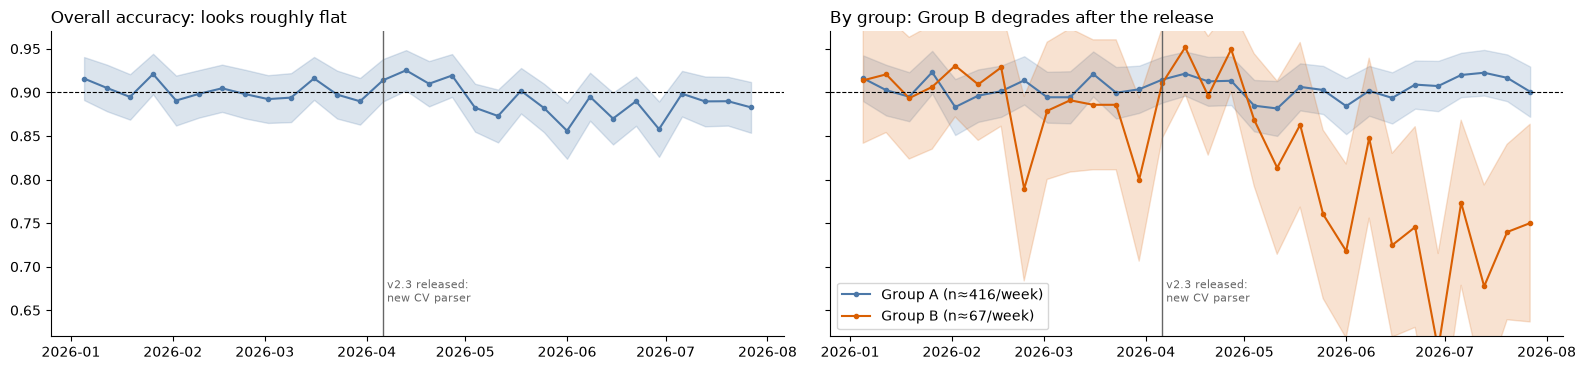

In [14]:
rs = np.random.default_rng(12)
wk = pd.date_range("2026-01-05", periods=30, freq="W-MON")
nA, nB = rs.integers(380, 460, 30), rs.integers(50, 80, 30)
pA = np.full(30, .90) + rs.normal(0, .004, 30)
pB = np.where(np.arange(30) < 14, .89, .89 - 0.012 * (np.arange(30) - 13)).clip(.65) + rs.normal(0, .004, 30)    # B degrades after week 14
accA, accB = rs.binomial(nA, pA) / nA, rs.binomial(nB, pB) / nB
acc_all = (accA * nA + accB * nB) / (nA + nB)
fig, ax = plt.subplots(1, 2, figsize=(16, 3.8), sharey=True)
se_all = np.sqrt(acc_all * (1 - acc_all) / (nA + nB))
ax[0].fill_between(wk, acc_all - 1.96 * se_all, acc_all + 1.96 * se_all, color=BLUE, alpha=.2); ax[0].plot(wk, acc_all, color=BLUE, marker="o", ms=3)
ax[0].axhline(.90, color="k", ls="--", lw=.8); ax[0].set_title("Overall accuracy: looks roughly flat", loc="left")
for acc_, n_, g_ in [(accA, nA, "A"), (accB, nB, "B")]:
    se_ = np.sqrt(acc_ * (1 - acc_) / n_); ax[1].fill_between(wk, acc_ - 1.96 * se_, acc_ + 1.96 * se_, color=GCOL[g_], alpha=.18); ax[1].plot(wk, acc_, color=GCOL[g_], marker="o", ms=3, label=f"Group {g_} (n≈{int(n_.mean())}/week)")
ev_date = wk[13]
for a_ in ax: a_.axvline(ev_date, color="#666", lw=1); a_.text(ev_date, .66, " v2.3 released:\n new CV parser", fontsize=8, color="#666")
ax[1].axhline(.90, color="k", ls="--", lw=.8); ax[1].legend(loc="lower left"); ax[1].set_title("By group: Group B degrades after the release", loc="left")
ax[0].set_ylim(.62, .97); plt.tight_layout(); plt.show()

## 10 · Monitoring distributions and prediction changes (delayed labels)

True outcomes often arrive **late** (here: interview results take 8 weeks), so accuracy lags. **Prediction and input distributions are available immediately** and can alert early. Use both: early proxies, later confirmation.

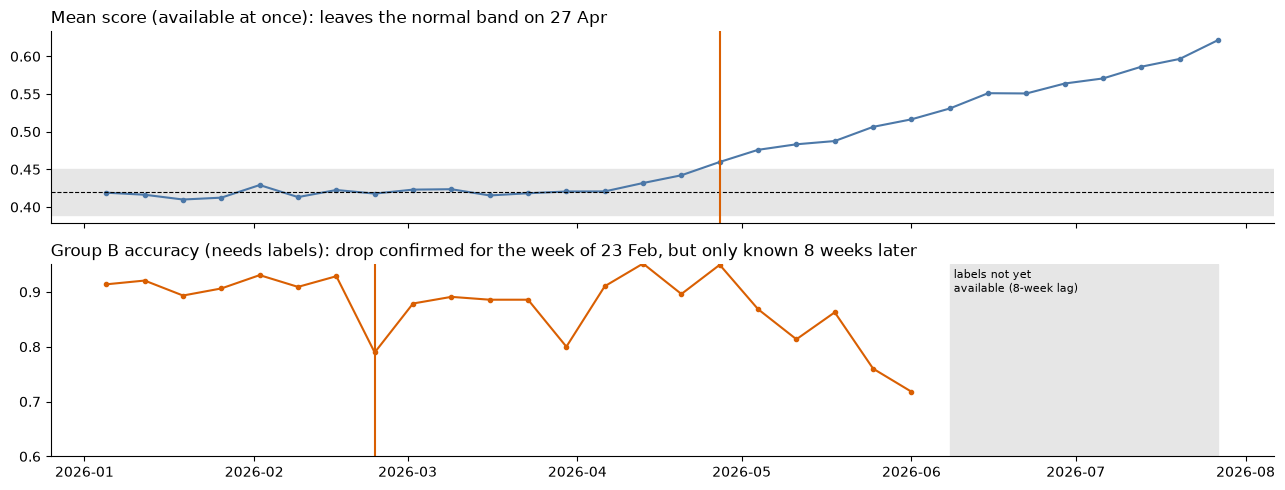

In [15]:
mean_score = np.where(np.arange(30) < 14, .42, .42 + .012 * (np.arange(30) - 13)) + rs.normal(0, .006, 30)
LAG = 8
fig, ax = plt.subplots(2, 1, figsize=(13, 5), sharex=True)
ax[0].plot(wk, mean_score, color=BLUE, marker="o", ms=3); ax[0].axhline(.42, color="k", ls="--", lw=.8); ax[0].axhspan(.42 - .03, .42 + .03, color=LIGHT)
first_alert = wk[np.argmax(np.abs(mean_score - .42) > .03)]; ax[0].axvline(first_alert, color=ACCENT); ax[0].set_title(f"Mean score (available at once): leaves the normal band on {first_alert:%d %b}", loc="left")
known = np.arange(30) < 30 - LAG
ax[1].plot(wk[known], accB[known], color=ACCENT, marker="o", ms=3); ax[1].plot(wk[~known], np.full((~known).sum(), np.nan))
ax[1].axvspan(wk[30 - LAG], wk[-1], color=LIGHT); ax[1].text(wk[30 - LAG], .9, " labels not yet\n available (8-week lag)", fontsize=8)
conf_alert = wk[np.argmax(accB < .84)]; ax[1].axvline(conf_alert, color=ACCENT)
ax[1].set_title(f"Group B accuracy (needs labels): drop confirmed for the week of {conf_alert:%d %b}, but only known 8 weeks later", loc="left"); ax[1].set_ylim(.6, .95)
plt.tight_layout(); plt.show()

## 11 · Designing a monitoring dashboard (Knaflic Ch. 3–4; Ware G8.6, Ch. 12)

**Declutter**; make the signal **salient only when it matters** (bring critical values to the eye rather than colouring everything); **small multiples sorted by drift**; draw thresholds lightly, label directly; avoid alert fatigue.

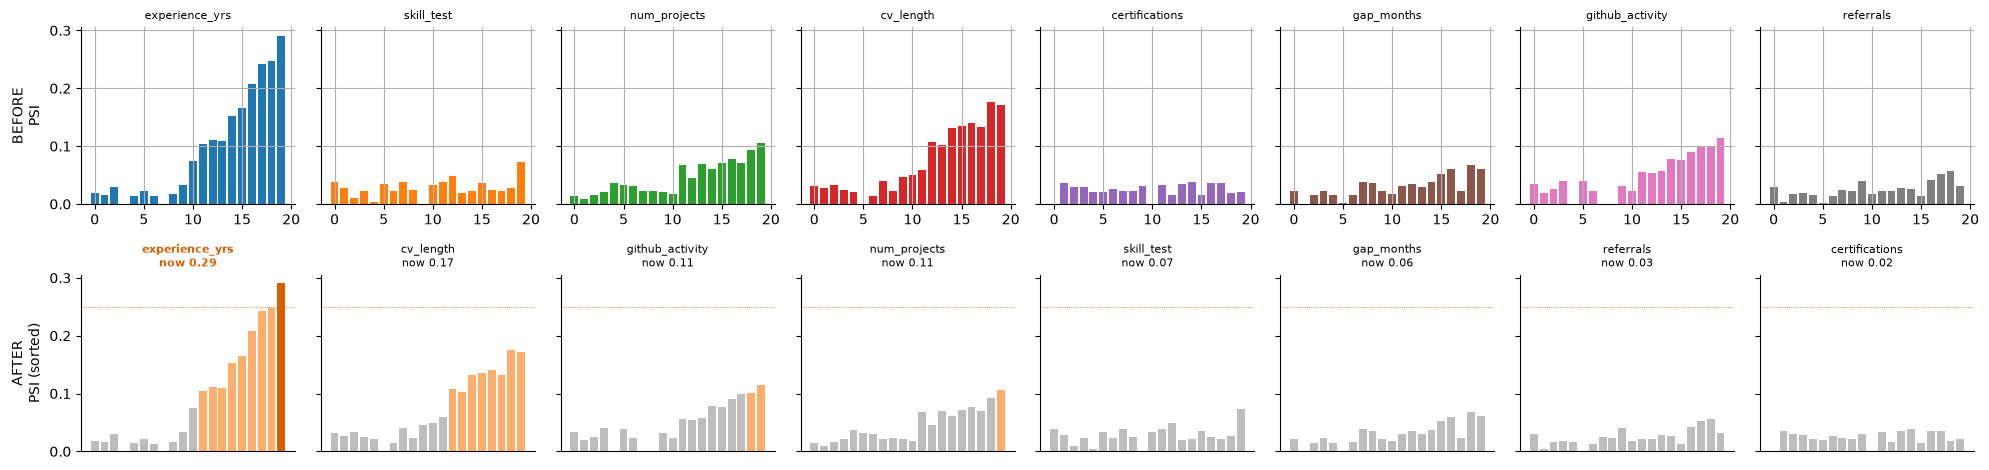

In [16]:
feat_names = ["experience_yrs", "skill_test", "num_projects", "cv_length", "certifications", "gap_months", "github_activity", "referrals"]
drift_w = rs.uniform(0, .6, 8); drift_w[[0, 3]] = [1.6, 1.1]
series = {f: np.clip(.02 + np.maximum(0, np.arange(20) - 8) * .014 * d_ + rs.normal(0, .012, 20), 0, None) for f, d_ in zip(feat_names, drift_w)}
fig, axs = plt.subplots(2, 8, figsize=(20, 4.8), sharey="row")
for a_, f in zip(axs[0], feat_names):
    a_.bar(range(20), series[f], color=plt.cm.tab10(feat_names.index(f))); a_.grid(True); a_.set_title(f, fontsize=8)
axs[0, 0].set_ylabel("BEFORE\nPSI")
order = sorted(feat_names, key=lambda f: -series[f][-1])
for a_, f in zip(axs[1], order):
    v = series[f]; col = np.where(v > .25, ACCENT, np.where(v > .1, "#fdae6b", GREY))
    a_.bar(range(20), v, color=col); a_.axhline(.25, color=ACCENT, lw=.6, ls=":"); a_.set_xticks([])
    a_.set_title(f"{f}\nnow {v[-1]:.2f}", fontsize=8, color=ACCENT if v[-1] > .25 else "k", fontweight="bold" if v[-1] > .25 else None)
axs[1, 0].set_ylabel("AFTER\nPSI (sorted)")
plt.tight_layout(); plt.show()

## 12 · Annotating drift events (Wilke Ch. 22; Knaflic Ch. 7)

A **title that states the finding**, the event annotated on the chart, and a **caption with the window, threshold and statistic**. Headlines that read in order should tell the story: what changed, when, what to do.

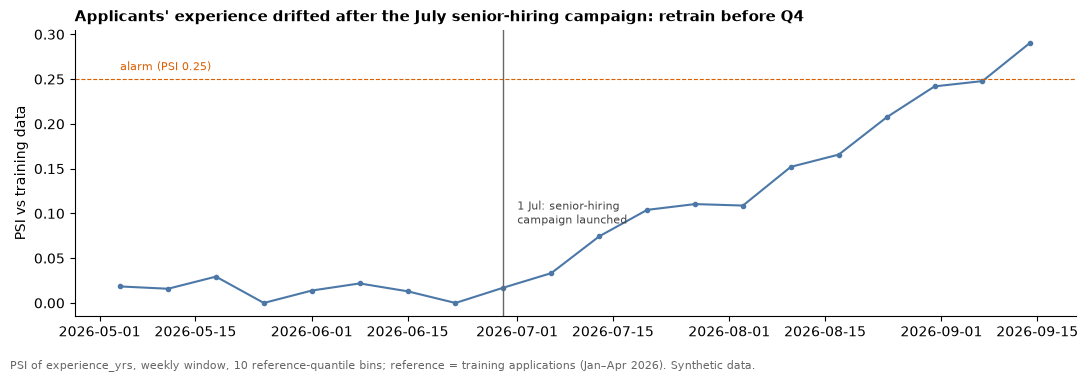

In [17]:
fig, ax = plt.subplots(figsize=(11, 3.6))
v = series["experience_yrs"]; wks = pd.date_range("2026-05-04", periods=20, freq="W-MON")
ax.plot(wks, v, color=BLUE, marker="o", ms=3); ax.axhline(.25, color=ACCENT, lw=.8, ls="--"); ax.text(wks[0], .26, "alarm (PSI 0.25)", color=ACCENT, fontsize=8)
ax.axvline(wks[8], color="#666", lw=1); ax.annotate("1 Jul: senior-hiring\ncampaign launched", (wks[8], .05), xytext=(10, 25), textcoords="offset points", fontsize=8, color="#444")
ax.set_title("Applicants' experience drifted after the July senior-hiring campaign: retrain before Q4", loc="left", fontweight="bold", fontsize=11)
ax.set_ylabel("PSI vs training data")
fig.text(.01, -.04, "PSI of experience_yrs, weekly window, 10 reference-quantile bins; reference = training applications (Jan–Apr 2026). Synthetic data.", fontsize=8, color="#666")
plt.tight_layout(); plt.show()

## 13 · AI-generated insight errors and hallucinations (Ji et al. 2023)

Generated summaries can sound fluent while being **wrong or unsupported**: invented numbers, wrong arithmetic, misread charts, wrong aggregation, causal claims the data cannot support. **Fluency is not evidence.** Treat every generated statement as a hypothesis: **recompute each number, check causal claims, show the evidence next to the claim.**

In [18]:
gen_summary = [
    ("The screener shortlists 41% of applicants.", lambda: f"{ev.shortlisted.mean():.0%}", "number"),
    ("Group B's shortlist rate is about half of Group A's.", lambda: f"ratio B/A = {gm.loc['B', 'selection rate'] / gm.loc['A', 'selection rate']:.2f}", "number"),
    ("Group B applicants are less qualified, which explains the gap.", lambda: f"base rates A {gm.loc['A', 'base rate']:.2f} vs B {gm.loc['B', 'base rate']:.2f}; TPR gap {gm.loc['A', 'TPR'] - gm.loc['B', 'TPR']:.2f} among the qualified", "causal"),
    ("Overall accuracy is stable at 90%, so no action is needed.", lambda: f"overall last 8 weeks {acc_all[-8:].mean():.2f}; Group B {accB[-8:].mean():.2f}", "aggregation"),
    ("Tier-1 college is the most important feature.", lambda: f"coefficients {dict(zip(feats, model.coef_[0].round(2)))}", "explanation"),
]
chk = []
for claim, f_, kind in gen_summary:
    chk.append((claim, kind, f_()))
display(pd.DataFrame(chk, columns=["generated claim", "kind", "recomputed evidence"]))
print("Verdicts are a human job: e.g. claim 3 is a causal claim the data contradicts (qualified B applicants are missed more often);")
print("claim 4 hides the Group B decline in an aggregate; claim 5 depends on feature scaling and correlated features (Section 16).")

,generated claim,kind,recomputed evidence
0,The screener shortlists 41% of applicants.,number,38%
1,Group B's shortlist rate is about half of Grou...,number,ratio B/A = 0.56
2,"Group B applicants are less qualified, which e...",causal,base rates A 0.47 vs B 0.45; TPR gap 0.22 amon...
3,"Overall accuracy is stable at 90%, so no actio...",aggregation,overall last 8 weeks 0.88; Group B 0.73
4,Tier-1 college is the most important feature.,explanation,"coefficients {'skill_test': np.float64(1.51), ..."


Verdicts are a human job: e.g. claim 3 is a causal claim the data contradicts (qualified B applicants are missed more often);
claim 4 hides the Group B decline in an aggregate; claim 5 depends on feature scaling and correlated features (Section 16).


## 14 · Misuse and limitations of automated insights: multiple comparisons

Tools that scan many variables will find **strong-looking patterns in pure noise**. With 20 independent tests at 5%, P(at least one false alarm) ≈ **64%**. Selecting the "most interesting" result exaggerates it. **Report how many comparisons were made.**

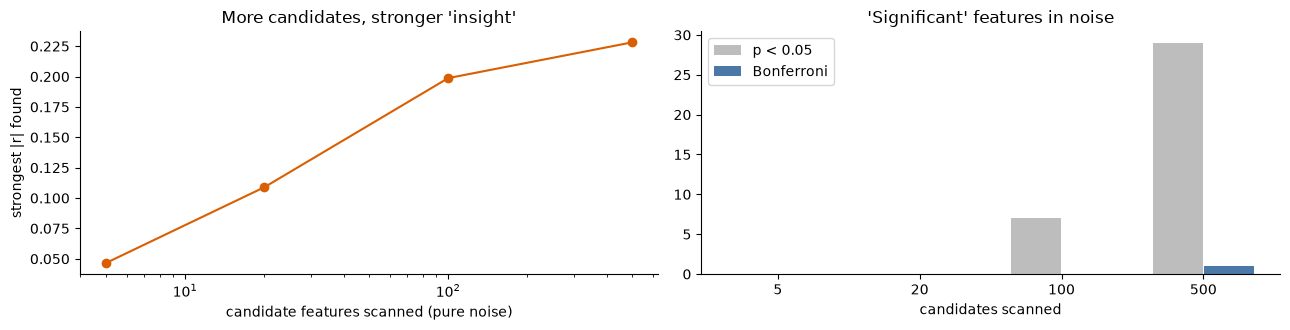

In [19]:
rs = np.random.default_rng(1)
n_app = 300; outcome = rs.normal(0, 1, n_app)
cands = [5, 20, 100, 500]
best_r, n_sig = [], []
for k_ in cands:
    Xn = rs.normal(0, 1, (n_app, k_)); r_ = np.array([np.corrcoef(Xn[:, j], outcome)[0, 1] for j in range(k_)])
    p_ = 2 * stats.t.sf(np.abs(r_ * np.sqrt((n_app - 2) / (1 - r_ ** 2))), n_app - 2)
    best_r.append(np.abs(r_).max()); n_sig.append(((p_ < .05).sum(), (p_ < .05 / k_).sum()))
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ax[0].plot(cands, best_r, marker="o", color=ACCENT); ax[0].set_xscale("log"); ax[0].set_xlabel("candidate features scanned (pure noise)"); ax[0].set_ylabel("strongest |r| found")
ax[0].set_title("More candidates, stronger 'insight'")
ax[1].bar(np.arange(4) - .18, [s[0] for s in n_sig], width=.35, color=GREY, label="p < 0.05"); ax[1].bar(np.arange(4) + .18, [s[1] for s in n_sig], width=.35, color=BLUE, label="Bonferroni")
ax[1].set_xticks(range(4)); ax[1].set_xticklabels(cands); ax[1].set_xlabel("candidates scanned"); ax[1].set_title("'Significant' features in noise"); ax[1].legend()
plt.tight_layout(); plt.show()

## 15 · Automation bias and over-trust (Parasuraman & Manzey 2010; Goddard et al. 2012)

People **over-rely on automated suggestions** and miss the errors the system makes; risk grows with workload and with a reliability record that hides rare failures. A small simulation: a reviewer checks AI shortlist decisions; with probability *trust* they simply accept the AI.

In [20]:
ai_correct = (ev.shortlisted == ev.qualified).values
rows = []
for trust in [0, .25, .5, .75, .9]:
    accept_blind = rs.random(len(ev)) < trust
    human_ok = rs.random(len(ev)) < .92                        # careful human review is right 92% of the time
    final_ok = np.where(accept_blind, ai_correct, human_ok)
    caught = ((~ai_correct) & ~accept_blind & human_ok).sum() / (~ai_correct).sum()
    rows.append((trust, final_ok.mean(), caught))
ab = pd.DataFrame(rows, columns=["share accepted without checking", "final accuracy", "AI errors caught"])
display(ab.round(3))
print("Counter-measures: show uncertainty and evidence, let the reviewer see raw data first (or record a judgement before seeing the AI), and feed back the model's real accuracy.")

,share accepted without checking,final accuracy,AI errors caught
0,0.00,0.926,0.922
1,0.25,0.860,0.685
2,0.50,0.802,0.450
3,0.75,0.750,0.228
4,0.90,0.710,0.082


Counter-measures: show uncertainty and evidence, let the reviewer see raw data first (or record a judgement before seeing the AI), and feed back the model's real accuracy.


## 16 · Explainability limitations (Adebayo et al. 2018; Rudin 2019)

Explanations are **approximations**; the same model family can yield **different attributions from run to run**, especially with correlated features. A single importance bar chart gives false reassurance: **show the spread across runs and call explanations hypotheses.** Rudin (2019): for high-stakes decisions prefer interpretable models over explaining black boxes.

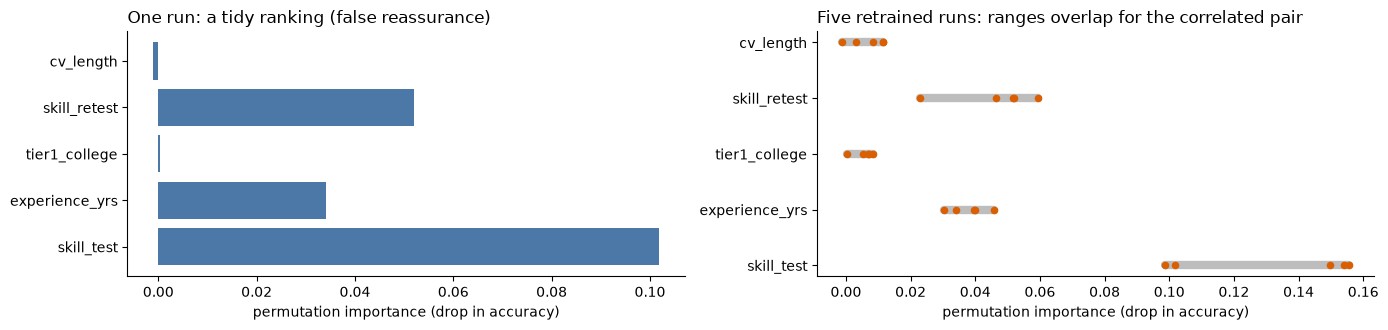

,skill_test,experience_yrs,tier1_college,skill_retest,cv_length
run 1,1,3,4,2,5
run 2,1,3,5,2,4
run 3,1,2,4,3,5
run 4,1,3,5,2,4
run 5,1,3,5,2,4


In [21]:
Xe = ev[["skill_test", "experience_yrs", "tier1_college"]].copy()
Xe["skill_retest"] = (Xe.skill_test + rs.normal(0, .15, len(Xe))).round(2)          # strongly correlated with skill_test
Xe["cv_length"] = rs.normal(2, .5, len(Xe)).round(1)                                  # irrelevant
imp = []
for s_ in range(5):
    Xa, Xb_, ya, yb = train_test_split(Xe, ev.qualified, test_size=.4, random_state=s_)
    rf = RandomForestClassifier(n_estimators=120, max_features=2, random_state=s_, n_jobs=-1).fit(Xa, ya)
    imp.append(permutation_importance(rf, Xb_, yb, n_repeats=5, random_state=s_).importances_mean)
imp = pd.DataFrame(imp, columns=Xe.columns)
fig, ax = plt.subplots(1, 2, figsize=(14, 3.4))
ax[0].barh(imp.columns, imp.iloc[0], color=BLUE); ax[0].set_title("One run: a tidy ranking (false reassurance)", loc="left")
for i, c in enumerate(imp.columns):
    ax[1].plot([imp[c].min(), imp[c].max()], [i, i], color=GREY, lw=6, solid_capstyle="round"); ax[1].scatter(imp[c], np.full(5, i), color=ACCENT, s=20, zorder=3)
ax[1].set_yticks(range(len(imp.columns))); ax[1].set_yticklabels(imp.columns); ax[1].set_title("Five retrained runs: ranges overlap for the correlated pair", loc="left")
for a_ in ax: a_.set_xlabel("permutation importance (drop in accuracy)")
plt.tight_layout(); plt.show()
display(imp.rank(axis=1, ascending=False).astype(int).rename(index=lambda i: f"run {i + 1}"))

## 17 · Uncertainty and ambiguity (Wilke Ch. 16)

**Uncertainty** is part of the data (error bars, bands, distributions; beware hard-boundary readings). **Ambiguity** is different: unclear definitions, labels or encodings allow more than one valid reading. **Do not resolve ambiguity silently**: state the definition used, and show alternatives where they change the conclusion. Example: "Has the shortlist rate for experienced applicants risen?" depends on what "experienced" means.

In [22]:
rows = []
for cut in [3, 5, 8]:
    for g_ in "AB":
        t = ev[(ev.group == g_) & (ev.experience_yrs >= cut)]
        rows.append((f"experienced = ≥ {cut} yrs", g_, len(t), t.shortlisted.mean()))
amb = pd.DataFrame(rows, columns=["definition", "group", "n", "shortlist rate"]).pivot(index="definition", columns="group", values=["shortlist rate", "n"])
amb[("gap A−B", "")] = amb[("shortlist rate", "A")] - amb[("shortlist rate", "B")]
display(amb.round(3))
print("The size of the gap depends on the definition; the figure caption must say which one was used.")

shortlist rate              n         gap A−B
group                              A      B       A       B        
definition                                                         
experienced = ≥ 3 yrs          0.572  0.353  1070.0  1344.0   0.219
experienced = ≥ 5 yrs          0.642  0.418   517.0   650.0   0.224
experienced = ≥ 8 yrs          0.756  0.604   131.0   169.0   0.152

The size of the gap depends on the definition; the figure caption must say which one was used.


## 18 · Human oversight and validating an AI-assisted visualization

Munzner §1.2–1.3: visualization lets people **check whether an automatic system is doing the right thing** by their own judgement, supports long-term monitoring and debugging, and helps when the problem is not fully specified. It is not the answer to every problem: automate repetitive checks; keep people for judgement.

**Nested model (Munzner Ch. 4)**: validate at four levels, each with its own threat.

| Level | Threat | Question for the screener |
|---|---|---|
| Domain | wrong problem | are we serving the people the system affects (applicants as well as recruiters)? |
| Data / task abstraction | wrong abstraction | is "past hire" a faithful proxy for "qualified"? (Section 2: no) |
| Visual idiom | wrong idiom | does the dashboard pool groups or hide denominators? |
| Algorithm | wrong algorithm | is the model biased, slow, or drifting? |

## 19 · Responsible AI-assisted visualization: principles and practice

| Principle | Visualization practice |
|---|---|
| Transparency | data sources, windows and limits on the figure; show uncertainty |
| Fairness | subgroup views with counts; show trade-offs between criteria |
| Human oversight | verification tools; evidence beside every AI claim |
| Robustness | drift monitoring and early-warning proxies |
| Accountability | owners, logs, model cards and datasheets |
| Privacy | aggregate or suppress small cells |

(EU HLEG 2019; NIST AI RMF 1.0, 2023; OECD 2019.) Responsibility is a **cycle**, not one chart: check data → evaluate by subgroup → show uncertainty → review → monitor → document → repeat.

### A model card with visual summaries (Mitchell et al. 2019; Gebru et al. 2021 for datasheets)

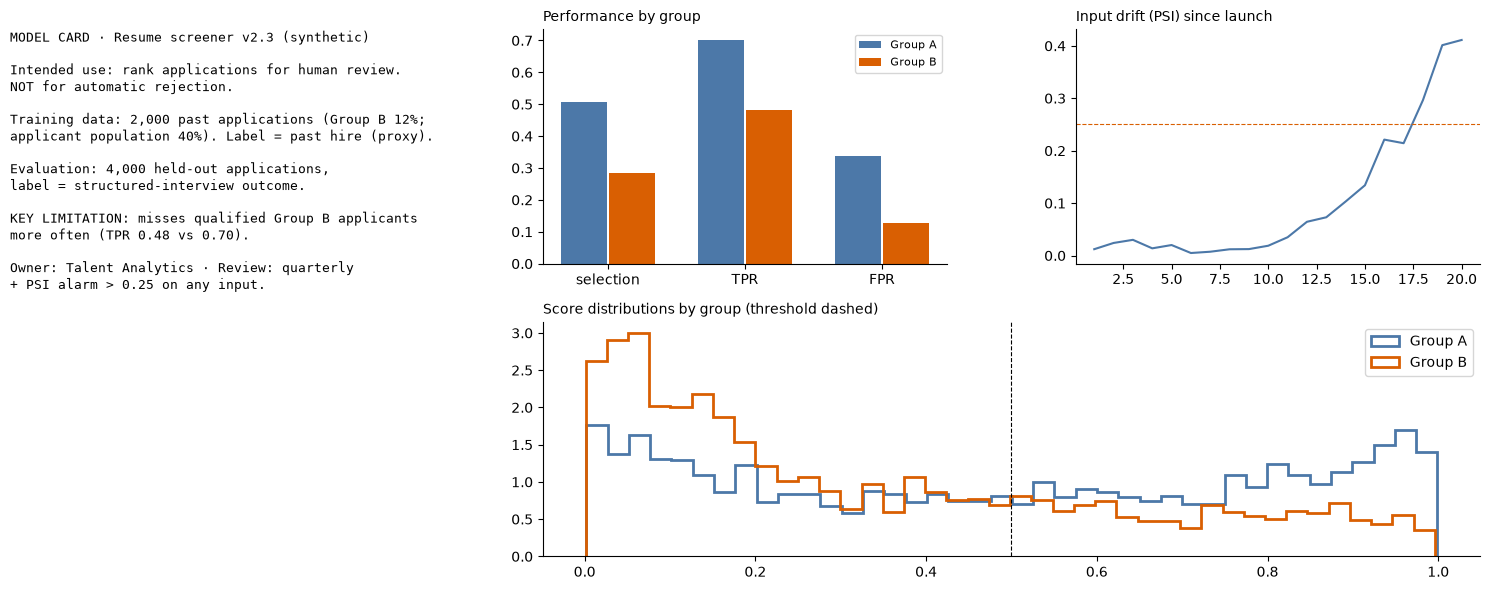

In [23]:
fig = plt.figure(figsize=(15, 6)); gs_ = fig.add_gridspec(2, 3)
t0 = fig.add_subplot(gs_[:, 0]); t0.axis("off")
card = (f"MODEL CARD · Resume screener v2.3 (synthetic)\n\n"
        f"Intended use: rank applications for human review.\nNOT for automatic rejection.\n\n"
        f"Training data: 2,000 past applications (Group B 12%;\napplicant population 40%). Label = past hire (proxy).\n\n"
        f"Evaluation: {len(ev):,} held-out applications,\nlabel = structured-interview outcome.\n\n"
        f"KEY LIMITATION: misses qualified Group B applicants\nmore often (TPR {gm.loc['B', 'TPR']:.2f} vs {gm.loc['A', 'TPR']:.2f}).\n\n"
        f"Owner: Talent Analytics · Review: quarterly\n+ PSI alarm > 0.25 on any input.")
t0.text(0, 1, card, va="top", fontsize=9.5, family="monospace")
a1 = fig.add_subplot(gs_[0, 1])
for i, g_ in enumerate("AB"):
    for k_, m_ in enumerate(["selection rate", "TPR", "FPR"]): a1.bar(k_ + (i - .5) * .35, gm.loc[g_, m_], width=.33, color=GCOL[g_], label=f"Group {g_}" if k_ == 0 else None)
a1.set_xticks(range(3)); a1.set_xticklabels(["selection", "TPR", "FPR"]); a1.legend(fontsize=8); a1.set_title("Performance by group", loc="left", fontsize=10)
a2 = fig.add_subplot(gs_[0, 2]); a2.plot(range(1, 21), psis, color=BLUE); a2.axhline(.25, color=ACCENT, ls="--", lw=.8); a2.set_title("Input drift (PSI) since launch", loc="left", fontsize=10)
a3 = fig.add_subplot(gs_[1, 1:])
for g_ in "AB": a3.hist(ev.score[ev.group == g_], bins=40, density=True, histtype="step", lw=2, color=GCOL[g_], label=f"Group {g_}")
a3.axvline(THR, color="k", ls="--", lw=.8); a3.legend(); a3.set_title("Score distributions by group (threshold dashed)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

## 20 · Visualization bias: ugly, bad and wrong figures (Wilke Ch. 1)

**Ugly**: aesthetic problems, but clear · **bad**: problems of perception (unclear, confusing, over-complicated, deceiving) · **wrong**: problems of mathematics (objectively incorrect). Common bias-creating choices: **hiding subgroups in an aggregate, cherry-picked time windows, inconsistent scales between panels, default thresholds shown as facts.** Document the choices behind a figure.

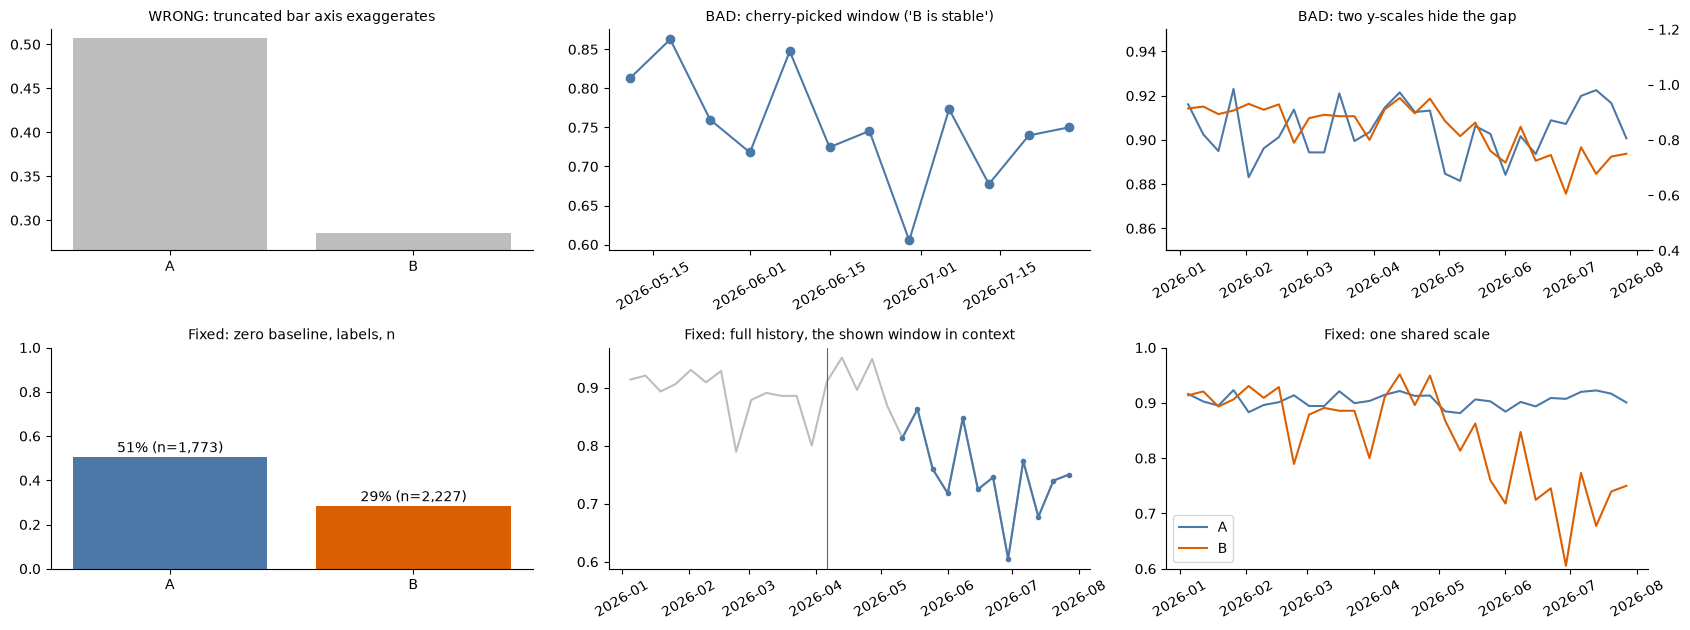

In [24]:
fig, ax = plt.subplots(2, 3, figsize=(17, 6.4))
sel = gm["selection rate"]
ax[0, 0].bar(sel.index, sel.values, color=GREY); ax[0, 0].set_ylim(sel.min() - .02, sel.max() + .01); ax[0, 0].set_title("WRONG: truncated bar axis exaggerates", fontsize=10)
ax[1, 0].bar(sel.index, sel.values, color=[GCOL[g_] for g_ in sel.index]); ax[1, 0].set_ylim(0, 1)
for g_, v in sel.items(): ax[1, 0].text(g_, v + .02, f"{v:.0%} (n={int(gm.loc[g_, 'n']):,})", ha="center")
ax[1, 0].set_title("Fixed: zero baseline, labels, n", fontsize=10)
ax[0, 1].plot(wk[18:], accB[18:], color=BLUE, marker="o"); ax[0, 1].set_title("BAD: cherry-picked window ('B is stable')", fontsize=10); ax[0, 1].tick_params(axis="x", rotation=30)
ax[1, 1].plot(wk, accB, color=GREY); ax[1, 1].plot(wk[18:], accB[18:], color=BLUE, marker="o", ms=3); ax[1, 1].axvline(ev_date, color="#666", lw=.8)
ax[1, 1].set_title("Fixed: full history, the shown window in context", fontsize=10); ax[1, 1].tick_params(axis="x", rotation=30)
ax[0, 2].plot(wk, accA, color=BLUE); ax[0, 2].set_ylim(.85, .95); ax2_ = ax[0, 2].twinx(); ax2_.plot(wk, accB, color=ACCENT); ax2_.set_ylim(.4, 1.2)
ax[0, 2].set_title("BAD: two y-scales hide the gap", fontsize=10)
ax[1, 2].plot(wk, accA, color=BLUE, label="A"); ax[1, 2].plot(wk, accB, color=ACCENT, label="B"); ax[1, 2].set_ylim(.6, 1); ax[1, 2].legend()
ax[1, 2].set_title("Fixed: one shared scale", fontsize=10)
for a_ in ax[:, 2]: a_.tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()

## 21 · Interpretation bias, clutter, attention and storytelling

* **Interpretation bias** (Ware Ch. 5): viewers notice what confirms their beliefs and anchor on the most salient item. Mitigate: show competing views and uncertainty, state limitations beside the finding, **record a judgement before seeing the model's answer**, test with real users.
* **Clutter** (Knaflic Ch. 3): every element adds cognitive load; Gestalt principles can create **false groups**. Declutter with alignment, white space and contrast.
* **Focus attention honestly** (Knaflic Ch. 4–5; Ware G1.2): is the emphasized item the *important* one, or merely the *favourable* one? **Do not headline overall accuracy while a subgroup gap sits unseen.**
* **Storytelling with care** (Knaflic Ch. 7): beginning (context), middle (what is happening), end (call to action); test with **horizontal logic**; the unfavourable parts belong in the story.
* **Cognitive efficiency** (Ware Ch. 12): start with an inventory of the data and its reliability; make the needed comparisons easy; evaluate with real failure cases.

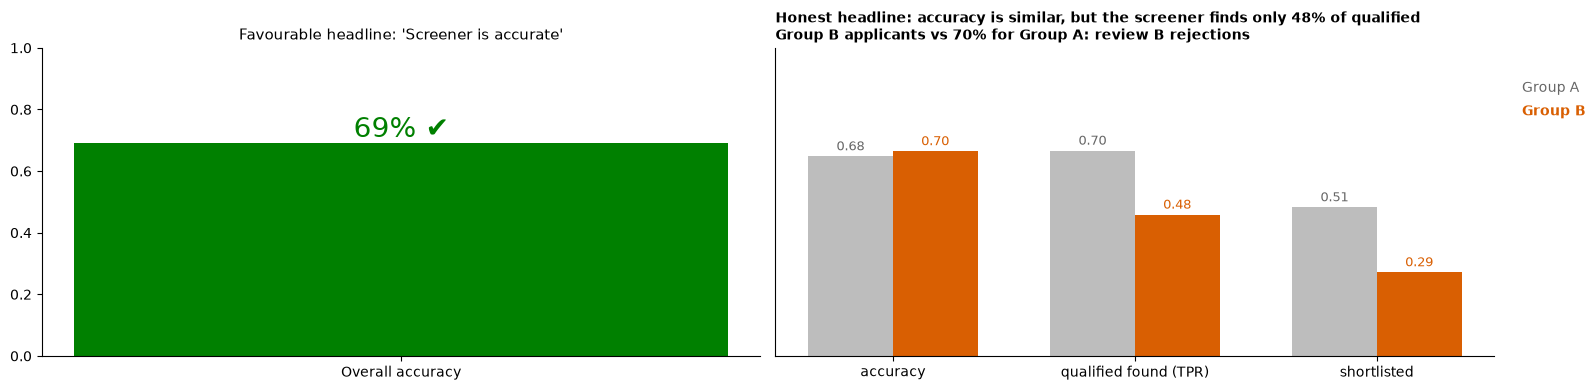

Horizontal logic: read only the headlines, in order
1. Context: the screener ranks 6,000 applications a quarter for recruiters.
2. Finding: it finds 70% of qualified Group A applicants but only 48% of Group B.
3. Why: it learnt from past hires, which over-rewarded Tier-1 colleges (a proxy label).
4. And it is drifting: applicant experience PSI passed 0.25 after July; Group B accuracy fell after v2.3.
5. Action: human review of Group B rejections now; retrain on interview outcomes; monitor by group.


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(16, 4))
acc_ev = (ev.shortlisted == ev.qualified).mean(); accg = ev.assign(ok=ev.shortlisted == ev.qualified).groupby("group").ok.mean()
ax[0].bar(["Overall accuracy"], [acc_ev], color="green", width=.4); ax[0].set_ylim(0, 1); ax[0].text(0, acc_ev + .02, f"{acc_ev:.0%} ✔", ha="center", fontsize=20, color="green")
ax[0].set_title("Favourable headline: 'Screener is accurate'", fontsize=11)
x_ = np.arange(3); w_ = .35
for k_, g_ in enumerate("AB"):
    vals = [accg[g_], gm.loc[g_, "TPR"], gm.loc[g_, "selection rate"]]
    ax[1].bar(x_ + (k_ - .5) * w_, vals, width=w_, color=GCOL[g_] if g_ == "B" else GREY)
    for xi, v in zip(x_, vals): ax[1].text(xi + (k_ - .5) * w_, v + .02, f"{v:.2f}", ha="center", fontsize=9, color=GCOL[g_] if g_ == "B" else "#666")
ax[1].set_xticks(x_); ax[1].set_xticklabels(["accuracy", "qualified found (TPR)", "shortlisted"]); ax[1].set_ylim(0, 1.05); ax[1].set_yticks([])
ax[1].text(2.6, .9, "Group A", color="#666"); ax[1].text(2.6, .82, "Group B", color=ACCENT, fontweight="bold")
ax[1].set_title(f"Honest headline: accuracy is similar, but the screener finds only {gm.loc['B', 'TPR']:.0%} of qualified\nGroup B applicants vs {gm.loc['A', 'TPR']:.0%} for Group A: review B rejections",
                loc="left", fontsize=10, fontweight="bold")
plt.tight_layout(); plt.show()
story = ["1. Context: the screener ranks 6,000 applications a quarter for recruiters.",
         f"2. Finding: it finds {gm.loc['A', 'TPR']:.0%} of qualified Group A applicants but only {gm.loc['B', 'TPR']:.0%} of Group B.",
         "3. Why: it learnt from past hires, which over-rewarded Tier-1 colleges (a proxy label).",
         "4. And it is drifting: applicant experience PSI passed 0.25 after July; Group B accuracy fell after v2.3.",
         "5. Action: human review of Group B rejections now; retrain on interview outcomes; monitor by group."]
print("Horizontal logic: read only the headlines, in order\n" + "\n".join(story))

## 22 · Worked numericals

### Numerical 1: population stability index
Reference shares 0.50, 0.30, 0.20; this week 0.35, 0.30, 0.35.

In [26]:
e_, a_ = np.array([.5, .3, .2]), np.array([.35, .3, .35])
terms = (a_ - e_) * np.log(a_ / e_)
for i, t_ in enumerate(terms): print(f"bin {i + 1}: ({a_[i]:.2f} − {e_[i]:.2f}) × ln({a_[i]:.2f}/{e_[i]:.2f}) = {t_:.4f}")
print(f"PSI = {terms.sum():.3f} -> moderate shift (0.10–0.25): investigate, not yet an alarm | MCQ 4: PSI 0.30 = significant shift")

bin 1: (0.35 − 0.50) × ln(0.35/0.50) = 0.0535
bin 2: (0.30 − 0.30) × ln(0.30/0.30) = 0.0000
bin 3: (0.35 − 0.20) × ln(0.35/0.20) = 0.0839
PSI = 0.137 -> moderate shift (0.10–0.25): investigate, not yet an alarm | MCQ 4: PSI 0.30 = significant shift


### Numerical 2: group fairness measures
Group A: 200 applicants, 100 qualified; approves 90 (80 qualified). Group B: 200 applicants, 50 qualified; approves 40 (30 qualified).

In [27]:
def fair(n, qual, approved, approved_qual):
    return dict(selection=approved / n, TPR=approved_qual / qual, FPR=(approved - approved_qual) / (n - qual))
fA, fB = fair(200, 100, 90, 80), fair(200, 50, 40, 30)
display(pd.DataFrame({"Group A": fA, "Group B": fB}).round(3))
print(f"equal-opportunity gap = {fA['TPR'] - fB['TPR']:.2f} | selection ratio B/A = {fB['selection'] / fA['selection']:.2f} (< 0.8 four-fifths rule of thumb)")

,Group A,Group B
selection,0.45,0.200
TPR,0.80,0.600
FPR,0.10,0.067


equal-opportunity gap = 0.20 | selection ratio B/A = 0.44 (< 0.8 four-fifths rule of thumb)


### Numerical 3: Simpson's paradox (kidney-stone data, Charig et al. 1986)

In [28]:
ks_ = pd.DataFrame({"treatment": ["A", "A", "B", "B"], "stone": ["small", "large", "small", "large"], "success": [81, 192, 234, 55], "n": [87, 263, 270, 80]})
ks_["rate"] = ks_.success / ks_.n
display(ks_.pivot(index="stone", columns="treatment", values="rate").round(2))
pooled = ks_.groupby("treatment")[["success", "n"]].sum(); pooled["rate"] = pooled.success / pooled.n
display(pooled.round(2))
print("A is better for small AND large stones, yet B looks better pooled: B was used mostly on easier small stones.")

treatment,A,B
stone,,
large,0.73,0.69
small,0.93,0.87


,success,n,rate
treatment,,,
A,273,350,0.78
B,289,350,0.83


A is better for small AND large stones, yet B looks better pooled: B was used mostly on easier small stones.


### Numerical 4: is the rolling accuracy really lower?
Baseline accuracy 0.90; latest window 0.84 with n = 200, then n = 1,000.

In [29]:
for n_ in (200, 1000):
    se = np.sqrt(.84 * .16 / n_); lo, hi = .84 - 1.96 * se, .84 + 1.96 * se
    print(f"n = {n_:5d}: SE = {se:.4f}; 95% interval {lo:.3f} to {hi:.3f}; baseline 0.90 {'just outside: weak evidence' if hi > .88 else 'clearly outside: strong evidence'}")

n =   200: SE = 0.0259; 95% interval 0.789 to 0.891; baseline 0.90 just outside: weak evidence
n =  1000: SE = 0.0116; 95% interval 0.817 to 0.863; baseline 0.90 clearly outside: strong evidence


### Numerical 5: multiple comparisons
20 independent tests at 5%, none real.

In [30]:
print(f"P(no false alarm) = 0.95^20 = {.95 ** 20:.3f}; P(at least one) = {1 - .95 ** 20:.2f}; expected false alarms = {20 * .05:.0f}; Bonferroni threshold = {.05 / 20:.4f}")
sim = (np.random.default_rng(0).random((20000, 20)) < .05).any(1).mean()
print(f"Simulation (20,000 scans of 20 null tests): at least one 'finding' in {sim:.0%} of scans")

P(no false alarm) = 0.95^20 = 0.358; P(at least one) = 0.64; expected false alarms = 1; Bonferroni threshold = 0.0025
Simulation (20,000 scans of 20 null tests): at least one 'finding' in 64% of scans


## Summary

| Theme | Take-away |
|---|---|
| **Bias** | enters through data, models, visualization choices and viewers; a figure must not mislead (Wilke Ch. 1) |
| **Sampling & subgroups** | check the sample against the population; compare groups with counts and intervals; beware aggregation (Simpson) |
| **Fairness** | selection rate, TPR, FPR, precision and calibration by group; criteria conflict when base rates differ: show the trade-off |
| **Drift** | data vs concept drift; PSI/KS with practical size; intervals on rolling metrics; early proxies because labels arrive late |
| **AI insights** | verify every generated number and causal claim; expect spurious patterns, over-trust and unstable explanations |
| **Oversight** | keep humans in the loop (Munzner Ch. 1); validate at four levels (Ch. 4); document with model cards |
| **Design** | declutter, focus attention honestly, tell the whole story including the unfavourable parts |

*Next: try the companion activity notebook, which uses a different synthetic dataset (`freshkart_paylater.csv`).*